# Real-Time Financial Fraud Detection — Model Training

**Stacking ensemble of XGBoost, LightGBM and CatBoost on the IEEE-CIS Fraud Detection dataset**

This notebook is the training stage of a real-time fraud detection system. It trains
the model on historical transactions and exports an artifact bundle (models,
preprocessing pipeline, feature list, decision threshold, manifest) that a streaming
Apache Flink job loads to score live transactions.

### Approach at a glance

| Step | What happens |
|---|---|
| Data | IEEE-CIS transactions joined with identity records (590,540 labelled transactions) |
| Split | Chronological: first 80% of transactions (in time order) for training, last 20% held out for the final test |
| Preprocessing | Median imputation (numeric), most-frequent imputation + ordinal encoding (categorical), fitted on training data only |
| Feature selection | Top 30 features by mean absolute SHAP value |
| Models | XGBoost, LightGBM and CatBoost; hyperparameters from Optuna on time-series cross-validation (stored best parameters are used by default, see Section 1) |
| Ensemble | Out-of-fold predictions stacked by an XGBoost meta-learner |
| Decision threshold | Chosen on a validation slice at the end of the training period |
| Evaluation | **ROC-AUC** and **accuracy** on the untouched holdout |

### Design choices

The modelling follows the stacking approach of arXiv:2505.10050, with three deliberate
changes that keep the evaluation honest and the model deployable:

1. **No oversampling (no SMOTE).** Class imbalance is handled with class weights
   (`scale_pos_weight` for XGBoost and LightGBM, `class_weights` for CatBoost). Evaluation
   data is never resampled.
2. **Time-based validation.** The model is trained on the past and evaluated on the
   future; cross-validation, tuning and stacking all use `TimeSeriesSplit`.
3. **Leak-safe, serving-safe preprocessing.** Imputers and encoders are fitted on training
   data only, and categories never seen in training map to a reserved code, so the same
   pipeline object can run unchanged in production.

### Contents

1. Configuration
2. Environment
3. Load and merge the data
4. Time-based split
5. Preprocessing pipeline
6. Feature selection with SHAP
7. Hyperparameter tuning
8. Stacking ensemble
9. Decision threshold
10. Final model
11. Holdout evaluation
12. Artifact bundle
13. Summary

## 1. Configuration

All settings live in one dictionary (`CFG`), which is saved in the manifest for
reproducibility.

**Hyperparameters — `warm_start_params`**

| Setting | What Section 7 does |
|---|---|
| As provided: best parameters for all three models from an earlier Optuna study | Uses these parameters directly. No tuning runs, which saves 450 model fits (30 trials × 5 folds × 3 models). |
| Empty dictionary: `"warm_start_params": {}` | No stored parameters, so it runs a 30-trial Optuna study for each of the three models, scored by ROC-AUC. |
| Only some models listed | Listed models use their stored parameters; the others are tuned. |

In [1]:
import os
import sys
import json
import time
import random
import hashlib
import platform
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# Kaggle mounts the competition data either under /kaggle/input or
# /kaggle/input/competitions depending on how it was attached.
# FRAUD_DATA_DIR / FRAUD_WORK_DIR optionally point elsewhere (e.g. a local run).
_CANDIDATE_DIRS = [
    os.environ.get("FRAUD_DATA_DIR", ""),
    "/kaggle/input/competitions/ieee-fraud-detection",
    "/kaggle/input/ieee-fraud-detection",
]
_DATA_DIR = next((d for d in _CANDIDATE_DIRS
                  if d and os.path.exists(os.path.join(d, "train_transaction.csv"))), None)
assert _DATA_DIR, f"train_transaction.csv not found in any of: {[d for d in _CANDIDATE_DIRS if d]}"
WORK_DIR = os.environ.get("FRAUD_WORK_DIR", "/kaggle/working")

CFG = {
    # --- paths ----------------------------------------------------------------
    "data_dir": _DATA_DIR,
    "out_dir": os.path.join(WORK_DIR, "artifacts"),
    "fig_dir": os.path.join(WORK_DIR, "figures"),
    # --- reproducibility --------------------------------------------------------
    "seed": 42,
    # --- splits -----------------------------------------------------------------
    "train_frac": 0.80,          # first 80% of the timeline = training, rest = holdout
    "val_frac_of_train": 0.10,   # last 10% of the training period = threshold-validation slice
    # --- feature selection ------------------------------------------------------
    "shap_sample_rows": 60_000,  # stratified sample used to compute SHAP values
    "top_k_features": 30,
    # --- tuning -------------------------------------------------------------------
    "optuna_trials": 30,
    "cv_folds": 5,               # TimeSeriesSplit folds (tuning and stacking)
    # --- serving contract ---------------------------------------------------------
    "unseen_category_code": -1,     # encoder code for categories not seen in training
    # --- warm start ---------------------------------------------------------------
    # Best parameters from an earlier Optuna study.
    # Models listed here skip tuning and use these parameters directly.
    # To tune all three models instead, replace the whole dictionary with an empty
    # one:  "warm_start_params": {}
    "warm_start_params": {
        "xgb": {
            "n_estimators": 400, "max_depth": 10,
            "learning_rate": 0.1205712628744377,
            "subsample": 0.8394633936788146,
            "colsample_bytree": 0.662397808134481,
            "scale_pos_weight": 17.039146842803188,
        },
        "lgbm": {
            "n_estimators": 700, "max_depth": 10,
            "learning_rate": 0.0156357101891512,
            "subsample": 0.6347712208051371,
            "colsample_bytree": 0.6888956883882508,
            "scale_pos_weight": 15.197908482119292,
        },
        "cat": {
            "n_estimators": 600, "max_depth": 9,
            "learning_rate": 0.041141781173145514,
            "subsample": 0.8687409187432332,
            "class_weight_pos": 15.878518147819292,
        },
    },
}

SEED = CFG["seed"]
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

Path(CFG["out_dir"]).mkdir(parents=True, exist_ok=True)
Path(CFG["fig_dir"]).mkdir(parents=True, exist_ok=True)

## 2. Environment

Library versions and hardware are recorded in the manifest. GPU-trained boosters are not
guaranteed to be bit-identical across hardware, so the GPU flag is recorded as well.
Every figure is displayed in the notebook and also saved to the `figures/` folder.

In [2]:
import sklearn
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import optuna
import shap
import scipy
import joblib
import matplotlib.pyplot as plt

VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "lightgbm": lgb.__version__,
    "catboost": cb.__version__,
    "optuna": optuna.__version__,
    "shap": shap.__version__,
    "scipy": scipy.__version__,
    "joblib": joblib.__version__,
}
print(json.dumps(VERSIONS, indent=2))

USE_GPU = os.system("nvidia-smi > /dev/null 2>&1") == 0
HARDWARE = {
    "platform": platform.platform(),
    "processor": platform.processor(),
    "gpu_detected": USE_GPU,
}
print("GPU detected:", USE_GPU)

optuna.logging.set_verbosity(optuna.logging.WARNING)


def save_and_show(fig, filename: str) -> None:
    """Save a figure to the figures folder and display it in the notebook."""
    fig.savefig(os.path.join(CFG["fig_dir"], filename), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def sha256_file(path: str, chunk: int = 1 << 20) -> str:
    """SHA-256 of a file, used to fingerprint the input data in the manifest."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

{
  "python": "3.13.16",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "lightgbm": "4.6.0",
  "catboost": "1.2.10",
  "optuna": "5.0.0",
  "shap": "0.54.1",
  "scipy": "1.16.3",
  "joblib": "1.6.0"
}
GPU detected: True


## 3. Load and merge the data

Identity records are left-joined onto transactions by `TransactionID`, which is then
dropped. Rows are sorted by `TransactionDT` (seconds from a reference time) so that every
later split respects time order.

Only the labelled `train_*.csv` files are used. The unlabelled competition `test_*.csv`
files are kept aside to simulate live traffic for the streaming job.

**Data contract.** Every non-null value in a categorical column is cast to `str` before
the pipeline runs. The streaming job applies the identical cast, so training and serving
see the same input types.

In [3]:
t0 = time.time()
DATA_DIR = CFG["data_dir"]
f_txn = os.path.join(DATA_DIR, "train_transaction.csv")
f_idn = os.path.join(DATA_DIR, "train_identity.csv")

DATA_HASHES = {
    "train_transaction.csv": sha256_file(f_txn),
    "train_identity.csv": sha256_file(f_idn),
}

txn = pd.read_csv(f_txn)
idn = pd.read_csv(f_idn)
df = txn.merge(idn, how="left", on="TransactionID")
del txn, idn

df = df.sort_values("TransactionDT", kind="mergesort").reset_index(drop=True)
df = df.drop(columns=["TransactionID"])

# Downcast float64 -> float32 to keep memory manageable.
float_cols = df.select_dtypes(include=["float64"]).columns
df[float_cols] = df[float_cols].astype(np.float32)

TARGET = "isFraud"
y_all = df[TARGET].astype(np.int8)
X_all = df.drop(columns=[TARGET])
del df

CAT_COLS = sorted(X_all.select_dtypes(include=["object"]).columns.tolist())
NUM_COLS = [c for c in X_all.columns if c not in CAT_COLS]


def coerce_categoricals(X: pd.DataFrame) -> pd.DataFrame:
    """Data contract: cast non-null categorical values to str (mirrored at serving time)."""
    X = X.copy()
    for c in CAT_COLS:
        col = X[c]
        mask = col.notna()
        X[c] = col.where(~mask, col[mask].astype(str))
    return X


X_all = coerce_categoricals(X_all)
print(f"Rows: {len(X_all):,} | numeric features: {len(NUM_COLS)} | "
      f"categorical features: {len(CAT_COLS)}")
print(f"Fraud prevalence: {y_all.mean():.4%}")
print(f"Load + merge: {time.time()-t0:.1f}s")

Rows: 590,540 | numeric features: 401 | categorical features: 31
Fraud prevalence: 3.4990%
Load + merge: 38.7s


## 4. Time-based split

The data is already sorted by `TransactionDT`:

| Split | Transactions (in time order) | Used for |
|---|---|---|
| Core-train | first 72% | tuning, out-of-fold stacking |
| Validation slice | next 8% (last 10% of the training split) | choosing the decision threshold |
| Holdout | last 20% | final evaluation, used exactly once |

Core-train plus the validation slice form the **training split** (first 80%).

In [4]:
n = len(X_all)
i_hold = int(n * CFG["train_frac"])                     # start of holdout
i_val = int(i_hold * (1.0 - CFG["val_frac_of_train"]))  # start of validation slice

X_train_full, y_train_full = X_all.iloc[:i_hold], y_all.iloc[:i_hold]
X_core, y_core = X_all.iloc[:i_val], y_all.iloc[:i_val]
X_val, y_val = X_all.iloc[i_val:i_hold], y_all.iloc[i_val:i_hold]
X_hold, y_hold = X_all.iloc[i_hold:], y_all.iloc[i_hold:]

SPLIT_INFO = {
    "n_total": int(n),
    "n_train_full": int(len(X_train_full)),
    "n_core_train": int(len(X_core)),
    "n_val": int(len(X_val)),
    "n_holdout": int(len(X_hold)),
    "transaction_dt_boundaries": {
        "train_end": float(X_train_full["TransactionDT"].iloc[-1]),
        "val_start": float(X_val["TransactionDT"].iloc[0]),
        "holdout_start": float(X_hold["TransactionDT"].iloc[0]),
    },
    "fraud_rate": {
        "train_full": float(y_train_full.mean()),
        "val": float(y_val.mean()),
        "holdout": float(y_hold.mean()),
    },
}
print(json.dumps(SPLIT_INFO, indent=2))
del X_all, y_all

{
  "n_total": 590540,
  "n_train_full": 472432,
  "n_core_train": 425188,
  "n_val": 47244,
  "n_holdout": 118108,
  "transaction_dt_boundaries": {
    "train_end": 12192842.0,
    "val_start": 10766698.0,
    "holdout_start": 12192900.0
  },
  "fraud_rate": {
    "train_full": 0.03513521522674162,
    "val": 0.03500973668614004,
    "holdout": 0.034409184813899145
  }
}


## 5. Preprocessing pipeline

One scikit-learn `ColumnTransformer`, fitted on the training split only:

- **numeric** → median imputation
- **categorical** → most-frequent imputation → ordinal encoding, with unseen categories
  mapped to the reserved code `-1`

This fitted object is the only pickled artifact. The streaming job loads and applies it
as-is, so preprocessing is never re-implemented in serving code.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

preprocessing = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
        (
            "cat",
            Pipeline(
                steps=[
                    ("impute", SimpleImputer(strategy="most_frequent")),
                    (
                        "encode",
                        OrdinalEncoder(
                            handle_unknown="use_encoded_value",
                            unknown_value=CFG["unseen_category_code"],
                            dtype=np.float32,
                        ),
                    ),
                ]
            ),
            CAT_COLS,
        ),
    ],
    verbose_feature_names_out=False,
)
preprocessing.set_output(transform="pandas")

preprocessing.fit(X_train_full)          # training split only, never the holdout
FEATURE_ORDER_ALL = list(preprocessing.get_feature_names_out())

P_core = preprocessing.transform(X_core)
P_val = preprocessing.transform(X_val)
print("Preprocessed core-train shape:", P_core.shape)

Preprocessed core-train shape: (425188, 432)


## 6. Feature selection with SHAP

An XGBoost classifier is trained on **all** features of the training split
(class-weighted, no resampling). SHAP values are computed on a stratified sample of
60,000 rows (`shap_sample_rows`), features are ranked by mean absolute SHAP value, and the
top 30 are kept (`top_k_features`). The ordered list is saved to `features.json`.

Top-30 features by mean |SHAP|:
['C13', 'TransactionAmt', 'card1', 'TransactionDT', 'C1', 'card2', 'V258', 'V70', 'card6', 'C14', 'addr1', 'C11', 'P_emaildomain', 'D1', 'V294', 'C5', 'C2', 'card5', 'D15', 'D10', 'M5', 'D4', 'M6', 'V91', 'dist1', 'D3', 'D2', 'C6', 'D11', 'R_emaildomain']


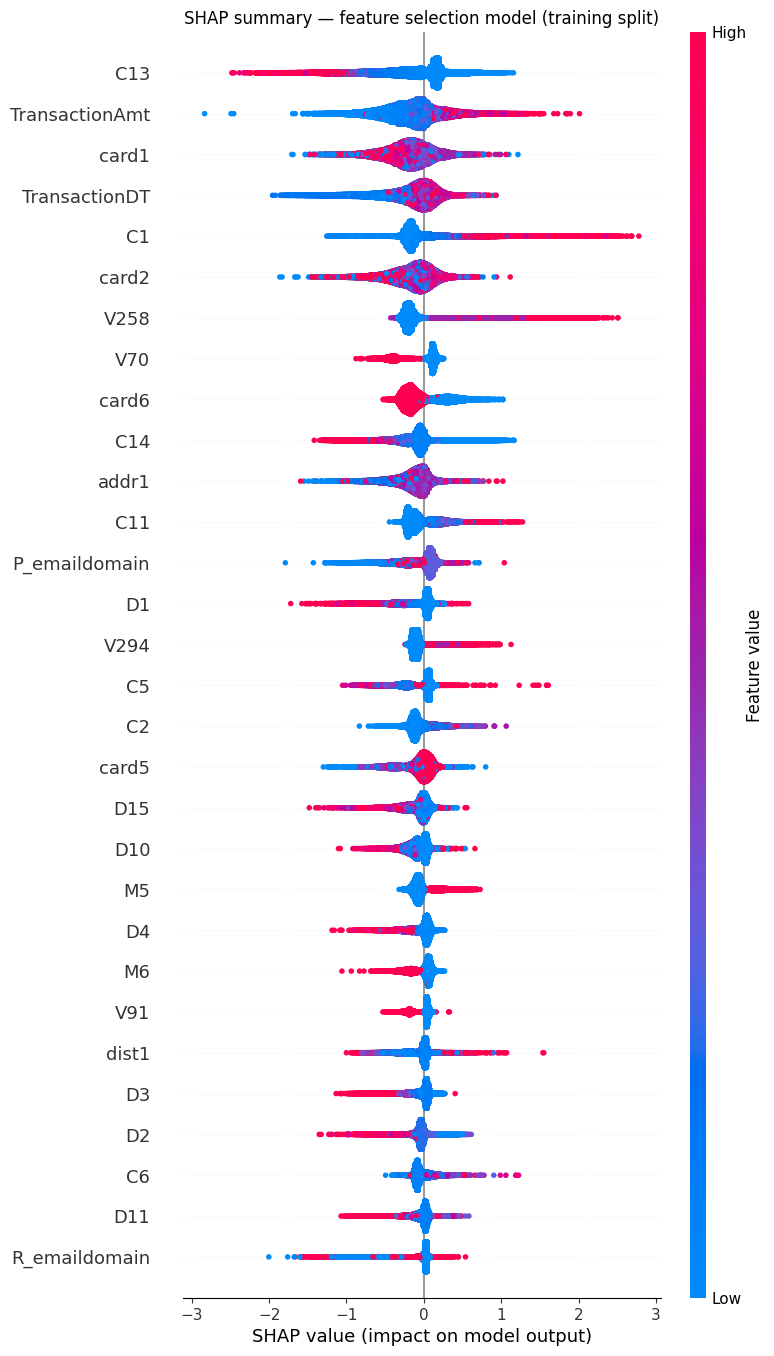

In [6]:
from sklearn.model_selection import train_test_split

P_train_full = preprocessing.transform(X_train_full)
spw_full = float((y_train_full == 0).sum() / max((y_train_full == 1).sum(), 1))

fs_model = xgb.XGBClassifier(
    n_estimators=400,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw_full,
    tree_method="hist",
    device="cuda" if USE_GPU else "cpu",
    random_state=SEED,
    n_jobs=-1,
    eval_metric="auc",
)
fs_model.fit(P_train_full, y_train_full)

X_shap, _, _, _ = train_test_split(
    P_train_full,
    y_train_full,
    train_size=min(CFG["shap_sample_rows"], len(P_train_full) - 1),
    stratify=y_train_full,
    random_state=SEED,
)
explainer = shap.TreeExplainer(fs_model)
shap_vals = explainer.shap_values(X_shap)
if isinstance(shap_vals, list):  # older SHAP versions return [class0, class1]
    shap_vals = shap_vals[1]

mean_abs_shap = np.abs(shap_vals).mean(axis=0)
rank = np.argsort(mean_abs_shap)[::-1]
SELECTED_FEATURES = [FEATURE_ORDER_ALL[i] for i in rank[: CFG["top_k_features"]]]
print(f"Top-{CFG['top_k_features']} features by mean |SHAP|:")
print(SELECTED_FEATURES)

plt.figure()
shap.summary_plot(shap_vals, X_shap, max_display=30, show=False)
plt.title("SHAP summary — feature selection model (training split)")
save_and_show(plt.gcf(), "shap_summary_feature_selection.png")

S_core = P_core[SELECTED_FEATURES]
S_val = P_val[SELECTED_FEATURES]
S_train_full = P_train_full[SELECTED_FEATURES]
del P_core, P_val, P_train_full, X_shap, shap_vals

## 7. Hyperparameter tuning

Each base model can have its own Optuna study (seeded TPE sampler, 30 trials). The
objective is the **mean ROC-AUC** over 5 `TimeSeriesSplit` folds of core-train, so every
fold is scored on data later than its training rows.

Tuned per model: number of trees, maximum depth, learning rate, row subsampling, column
subsampling (XGBoost and LightGBM; CatBoost on CPU only) and the positive-class weight.

A study runs only for models that are **not** listed in `warm_start_params` (Section 1).
With the configuration as provided, all three models use their stored parameters and no
study runs; with `"warm_start_params": {}`, all three are tuned here.

In [7]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score

tscv = TimeSeriesSplit(n_splits=CFG["cv_folds"])
spw_core = float((y_core == 0).sum() / max((y_core == 1).sum(), 1))


def make_model(name: str, params: dict):
    """Build an unfitted base model from constructor parameters."""
    if name == "xgb":
        return xgb.XGBClassifier(
            **params,
            tree_method="hist",
            device="cuda" if USE_GPU else "cpu",
            random_state=SEED,
            n_jobs=-1,
            eval_metric="auc",
        )
    if name == "lgbm":
        return lgb.LGBMClassifier(**params, random_state=SEED, n_jobs=-1, verbosity=-1)
    if name == "cat":
        w = params.pop("class_weight_pos")
        return cb.CatBoostClassifier(
            **params,
            class_weights=[1.0, w],
            bootstrap_type="Bernoulli",       # the GPU default (Bayesian) does not accept subsample
            task_type="GPU" if USE_GPU else "CPU",
            random_seed=SEED,
            verbose=False,
            allow_writing_files=False,
        )
    raise ValueError(name)


def suggest_params(name: str, trial: optuna.Trial) -> dict:
    """Optuna search space for each base model."""
    common = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800, step=100),
        "max_depth": trial.suggest_int("max_depth", 4, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
    }
    w = trial.suggest_float("pos_weight", 0.5 * spw_core, 2.0 * spw_core, log=True)
    if name == "xgb":
        return {**common,
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
                "scale_pos_weight": w}
    if name == "lgbm":
        return {**common,
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
                "scale_pos_weight": w}
    if name == "cat":
        common["max_depth"] = min(common["max_depth"], 10)
        params = {**common, "class_weight_pos": w}
        if not USE_GPU:
            # colsample_bylevel (rsm) is not reliably supported on CatBoost GPU.
            params["colsample_bylevel"] = trial.suggest_float("colsample_bytree", 0.6, 1.0)
        return params
    raise ValueError(name)


def cv_roc_auc(name: str, params: dict) -> float:
    """Mean ROC-AUC over time-series folds of core-train."""
    scores = []
    for tr_idx, te_idx in tscv.split(S_core):
        m = make_model(name, dict(params))
        m.fit(S_core.iloc[tr_idx], y_core.iloc[tr_idx])
        p = m.predict_proba(S_core.iloc[te_idx])[:, 1]
        scores.append(roc_auc_score(y_core.iloc[te_idx], p))
    return float(np.mean(scores))


BEST_PARAMS = {}
PARAM_SOURCE = {}
for name in ["xgb", "lgbm", "cat"]:
    ws = CFG.get("warm_start_params", {}).get(name)
    if ws:
        BEST_PARAMS[name] = dict(ws)
        PARAM_SOURCE[name] = "warm_start"
        print(f"[{name}] using stored parameters (tuning skipped): {ws}")
        continue
    PARAM_SOURCE[name] = "optuna"
    t1 = time.time()
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        study_name=f"tune_{name}",
    )
    study.optimize(
        lambda tr, _n=name: cv_roc_auc(_n, suggest_params(_n, tr)),
        n_trials=CFG["optuna_trials"],
        show_progress_bar=False,
    )
    # Rebuild the concrete constructor parameters from the best trial.
    best_trial = study.best_trial
    BEST_PARAMS[name] = suggest_params(name, optuna.trial.FixedTrial(best_trial.params))
    print(f"[{name}] best mean CV ROC-AUC={study.best_value:.4f} "
          f"({time.time()-t1:.0f}s) params={best_trial.params}")

[xgb] using stored parameters (tuning skipped): {'n_estimators': 400, 'max_depth': 10, 'learning_rate': 0.1205712628744377, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.662397808134481, 'scale_pos_weight': 17.039146842803188}
[lgbm] using stored parameters (tuning skipped): {'n_estimators': 700, 'max_depth': 10, 'learning_rate': 0.0156357101891512, 'subsample': 0.6347712208051371, 'colsample_bytree': 0.6888956883882508, 'scale_pos_weight': 15.197908482119292}
[cat] using stored parameters (tuning skipped): {'n_estimators': 600, 'max_depth': 9, 'learning_rate': 0.041141781173145514, 'subsample': 0.8687409187432332, 'class_weight_pos': 15.878518147819292}


## 8. Stacking ensemble

The three base models, with the hyperparameters from Section 7, produce **out-of-fold**
predictions over time-series folds, so each row's meta-features come only from models
trained on earlier data. An XGBoost meta-learner is trained on these three scores.

With `TimeSeriesSplit`, rows before the first fold boundary never receive an out-of-fold
prediction; the meta-learner is trained on the covered rows only.

The stack is built twice: here on core-train (to choose the threshold on the validation
slice in Section 9), and again on the full training split for the final model (Section 10).

In [8]:
BASE_NAMES = ["xgb", "lgbm", "cat"]


def build_oof(S: pd.DataFrame, y: pd.Series):
    """Out-of-fold meta-features over time-series folds -> (meta_X, meta_y, covered_mask)."""
    oof = np.full((len(S), len(BASE_NAMES)), np.nan, dtype=np.float64)
    for tr_idx, te_idx in tscv.split(S):
        for j, name in enumerate(BASE_NAMES):
            m = make_model(name, dict(BEST_PARAMS[name]))
            m.fit(S.iloc[tr_idx], y.iloc[tr_idx])
            oof[te_idx, j] = m.predict_proba(S.iloc[te_idx])[:, 1]
    covered = ~np.isnan(oof).any(axis=1)
    return oof[covered], y.iloc[covered].to_numpy(), covered


def make_meta():
    """Meta-learner: a small XGBoost classifier, as in the reference paper."""
    return xgb.XGBClassifier(
        n_estimators=200,
        max_depth=2,
        learning_rate=0.1,
        tree_method="hist",
        device="cpu",
        random_state=SEED,
        n_jobs=-1,
        eval_metric="auc",
    )


def fit_bases(S: pd.DataFrame, y: pd.Series) -> dict:
    return {name: make_model(name, dict(BEST_PARAMS[name])).fit(S, y)
            for name in BASE_NAMES}


def stack_proba(bases: dict, meta, S: pd.DataFrame) -> np.ndarray:
    """Fraud probability from the full stack."""
    meta_X = np.column_stack([bases[nm].predict_proba(S)[:, 1] for nm in BASE_NAMES])
    return meta.predict_proba(meta_X)[:, 1]


# Core-train stack: used only to choose the decision threshold.
t2 = time.time()
oof_X_core, oof_y_core, _ = build_oof(S_core, y_core)
meta_core = make_meta().fit(oof_X_core, oof_y_core)
bases_core = fit_bases(S_core, y_core)
print(f"Core-train stack fitted in {time.time()-t2:.0f}s "
      f"(meta-learner rows: {len(oof_y_core):,})")

Core-train stack fitted in 183s (meta-learner rows: 354,320)


## 9. Decision threshold

The validation slice (the end of the training period) is scored by the core-train
stack — models that have never seen these rows. The threshold that maximizes the F1 score
on this slice becomes the production decision threshold: transactions with a fraud
probability at or above it are flagged as fraud. The holdout is still untouched.

In [9]:
from sklearn.metrics import precision_recall_curve, accuracy_score

val_proba = stack_proba(bases_core, meta_core, S_val)
prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
THRESHOLD = float(thr[int(np.argmax(f1))])

print(f"Decision threshold: {THRESHOLD:.4f}")
print(f"Validation ROC-AUC: {roc_auc_score(y_val, val_proba):.4f}")
print(f"Validation accuracy at threshold: "
      f"{accuracy_score(y_val, (val_proba >= THRESHOLD).astype(np.int8)):.4f}")

Decision threshold: 0.3049
Validation ROC-AUC: 0.9407
Validation accuracy at threshold: 0.9759


## 10. Final model

The base models are refit on the full training split (core-train + validation slice),
and the meta-learner is retrained on out-of-fold predictions over the full training
split. The threshold from Section 9 is kept: it was chosen on forward-in-time data before
this refit and is recorded in `threshold.json`.

In [10]:
t3 = time.time()
oof_X_full, oof_y_full, _ = build_oof(S_train_full, y_train_full)
meta_final = make_meta().fit(oof_X_full, oof_y_full)
bases_final = fit_bases(S_train_full, y_train_full)
print(f"Final stack fitted in {time.time()-t3:.0f}s "
      f"(meta-learner rows: {len(oof_y_full):,})")

Final stack fitted in 192s (meta-learner rows: 393,690)


## 11. Holdout evaluation

The holdout — the last 20% of transactions in time order, with its original class balance and no
resampling — is used exactly once, here. Two metrics are reported:

- **ROC-AUC**: how well the fraud probability ranks fraudulent above legitimate
  transactions, independent of the threshold.
- **Accuracy**: share of correct fraud / non-fraud decisions at the chosen threshold.
  Because only a few percent of transactions are fraud, accuracy should be read together
  with ROC-AUC and the confusion matrix.

As a leakage guard, ROC-AUC above 0.98 or accuracy above 0.995 on this time-based,
unresampled holdout triggers a warning.

{
  "roc_auc": 0.917100325252624,
  "accuracy": 0.9720848714735666
}


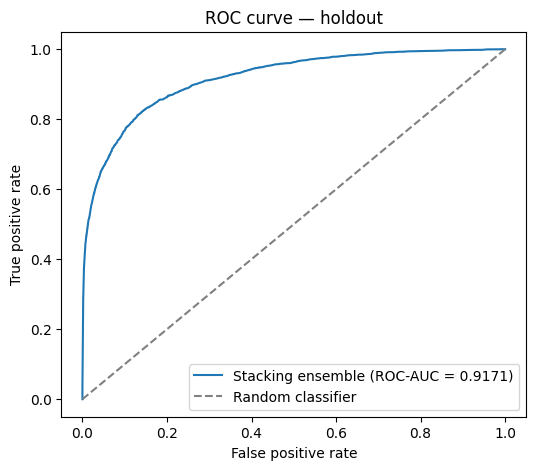

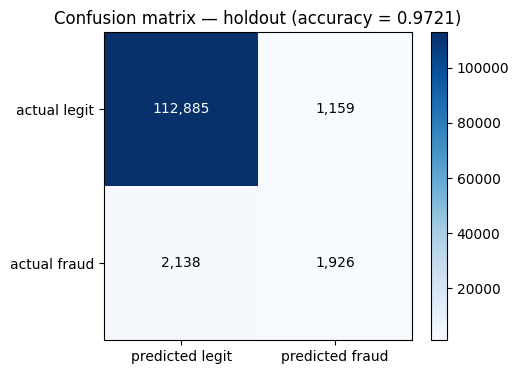

In [11]:
from sklearn.metrics import confusion_matrix, roc_curve

S_hold = preprocessing.transform(X_hold)[SELECTED_FEATURES]
hold_proba = stack_proba(bases_final, meta_final, S_hold)
hold_pred = (hold_proba >= THRESHOLD).astype(np.int8)

METRICS = {
    "roc_auc": float(roc_auc_score(y_hold, hold_proba)),
    "accuracy": float(accuracy_score(y_hold, hold_pred)),
}
print(json.dumps(METRICS, indent=2))

if METRICS["roc_auc"] > 0.98 or METRICS["accuracy"] > 0.995:
    print("\n" + "!" * 78)
    print("WARNING: metrics this high on a time-based, unresampled holdout almost "
          "certainly indicate a LEAKAGE BUG. Do not ship these artifacts — investigate.")
    print("!" * 78)

# ROC curve
fpr, tpr, _ = roc_curve(y_hold, hold_proba)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"Stacking ensemble (ROC-AUC = {METRICS['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random classifier")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve — holdout")
ax.legend(loc="lower right")
save_and_show(fig, "roc_holdout.png")

# Confusion matrix at the decision threshold
cm = confusion_matrix(y_hold, hold_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center",
            color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["predicted legit", "predicted fraud"])
ax.set_yticklabels(["actual legit", "actual fraud"])
ax.set_title(f"Confusion matrix — holdout (accuracy = {METRICS['accuracy']:.4f})")
fig.colorbar(im)
save_and_show(fig, "confusion_matrix_holdout.png")

## 12. Artifact bundle

Everything the streaming job needs to score live transactions.

| File | Content |
|---|---|
| `model_xgb.json`, `model_lgbm.txt`, `model_catboost.cbm` | base models, native formats |
| `meta_learner.json` | XGBoost meta-learner, native format |
| `preprocessing.pkl` | fitted preprocessing pipeline (the only pickled object; pin the same scikit-learn version at serving time) |
| `features.json` | ordered list of the 30 selected features |
| `threshold.json` | decision threshold and the order of meta-features |
| `manifest.json` | versions, data hashes, split, configuration, hyperparameters, holdout metrics |

In [12]:
OUT = CFG["out_dir"]

# Models — native formats.
bases_final["xgb"].save_model(os.path.join(OUT, "model_xgb.json"))
bases_final["lgbm"].booster_.save_model(os.path.join(OUT, "model_lgbm.txt"))
bases_final["cat"].save_model(os.path.join(OUT, "model_catboost.cbm"))
meta_final.save_model(os.path.join(OUT, "meta_learner.json"))

# Preprocessing pipeline — the single pickled artifact.
joblib.dump(preprocessing, os.path.join(OUT, "preprocessing.pkl"))

# Ordered feature list.
with open(os.path.join(OUT, "features.json"), "w") as f:
    json.dump({"selected_features": SELECTED_FEATURES,
               "selection_method": f"mean |SHAP| top-{CFG['top_k_features']} "
                                   f"(XGBoost on all features, training split)"},
              f, indent=2)

# Decision threshold + provenance.
with open(os.path.join(OUT, "threshold.json"), "w") as f:
    json.dump({
        "threshold": THRESHOLD,
        "selection": "F1-maximizing threshold",
        "selected_on": "validation slice = last 10% of the training period "
                       "(forward-in-time), scored by the core-train stack",
        "base_model_order_for_meta_features": BASE_NAMES,
    }, f, indent=2)

# Manifest.
MODEL_VERSION = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
manifest = {
    "model_version": MODEL_VERSION,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "versions": VERSIONS,
    "hardware": HARDWARE,
    "data_sha256": DATA_HASHES,
    "data_contract": {
        "categorical_columns": CAT_COLS,
        "numeric_columns_count": len(NUM_COLS),
        "categorical_coercion": "non-null categorical values cast to str before pipeline",
        "unseen_category_code": CFG["unseen_category_code"],
    },
    "split": SPLIT_INFO,
    "config": CFG,
    "selected_features": SELECTED_FEATURES,
    "hyperparameters": {k: {p: (int(v) if isinstance(v, (int, np.integer)) else
                                float(v) if isinstance(v, (float, np.floating)) else v)
                            for p, v in prm.items()}
                        for k, prm in BEST_PARAMS.items()},
    "hyperparameter_source": PARAM_SOURCE,
    "meta_learner": {"type": "XGBClassifier",
                     "n_estimators": 200, "max_depth": 2, "learning_rate": 0.1},
    "threshold": THRESHOLD,
    "holdout_metrics": METRICS,
    "design_choices": [
        "No oversampling: class weighting only; evaluation data never resampled",
        "Time-based split on TransactionDT; TimeSeriesSplit for tuning and stacking",
        "Leak-safe preprocessing fitted on training data; reserved code for unseen categories",
        "Holdout metrics: ROC-AUC and accuracy",
    ],
}
with open(os.path.join(OUT, "manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2, default=str)

print("Artifacts written to", OUT)
for p in sorted(Path(OUT).iterdir()):
    print(f"  {p.name:22s} {p.stat().st_size/1e6:8.2f} MB")
print("\nModel version:", MODEL_VERSION)

Artifacts written to /kaggle/working/artifacts
  features.json              0.00 MB
  manifest.json              0.00 MB
  meta_learner.json          0.16 MB
  model_catboost.cbm         4.99 MB
  model_lgbm.txt             2.48 MB
  model_xgb.json            16.92 MB
  preprocessing.pkl          0.06 MB
  threshold.json             0.00 MB

Model version: 20261106T163612Z


## 13. Summary

Key facts and holdout results from this run.

In [13]:
from IPython.display import display

summary = pd.DataFrame(
    {
        "Value": [
            f"{SPLIT_INFO['n_train_full']:,}",
            f"{SPLIT_INFO['n_holdout']:,}",
            f"{len(SELECTED_FEATURES)}",
            "XGBoost + LightGBM + CatBoost → XGBoost meta-learner",
            f"{THRESHOLD:.4f}",
            f"{METRICS['roc_auc']:.4f}",
            f"{METRICS['accuracy']:.4f}",
        ]
    },
    index=[
        "Training transactions",
        "Holdout transactions",
        "Selected features",
        "Model",
        "Decision threshold",
        "Holdout ROC-AUC",
        "Holdout accuracy",
    ],
)
display(summary)
print("Artifacts:", OUT)
print("Figures:  ", CFG["fig_dir"])

,Value
Training transactions,"472,432"
Holdout transactions,"118,108"
Selected features,30
Model,XGBoost + LightGBM + CatBoost → XGBoost meta-l...
Decision threshold,0.3049
Holdout ROC-AUC,0.9171
Holdout accuracy,0.9721


Artifacts: /kaggle/working/artifacts
Figures:   /kaggle/working/figures
